# Lab 04 — Unsupervised learning I: clustering and PCA

*Customer segments from two years of invoices, and a compressed view of 15,701 wood-defect images*

**Goal.** Turn raw invoice lines into one row per customer, find segments with K-means and DBSCAN and judge them by evidence and usefulness, then compress images with PCA and choose how much to keep by validation, testing once.

**Data.** `all_datasets/unsupervised/online_retail_ii/online_retail_ii.zip`, `all_datasets/unsupervised/wood_surface_defects/wood_defects.npz`

**Reading.** Chapters 15 to 17: how unsupervised learning works, clustering, dimensionality reduction.

**Run.** From the course folder, start `jupyter lab`, open `all_experiments/lab04_clustering_pca/lab04_clustering_pca_worked.ipynb`, and choose **Restart Kernel and Run All Cells**. The same code runs as a script: `python all_experiments/lab04_clustering_pca/lab04_clustering_pca_worked.py`.

**Evidence.** `results/lab04/` — K-means diagnostics, the customer segments, the PCA variance curve, `metrics.csv` and the figures

**Your map of this lab**

| Part | What you do | Questions |
| --- | --- | --- |
| A | Build customer rows, segment them with $K$-means, find outliers with DBSCAN | 2–6 |
| B | Compress wood-defect images with PCA, choose the budget, test once and save | 7–11 |
| Finish | Save the evidence; then cluster the defect images | 12–14 |
| After | Your-turn tasks, expected findings, troubleshooting and the two checklists (on the lab sheet) | — |

## Setup

Imports and paths. `start_lab()`, from `all_experiments/course_setup.py`, finds the course folder by looking upward for `all_datasets/`; figures and tables go to `results/lab04/`, and the saved model to `models/`.

### Question 1 — Setup

In [1]:
# 1. The course helper: finds the course folder and prepares the output folders.
import sys
sys.path.insert(0, "..")                     # all_experiments/, where course_setup.py lives
from course_setup import start_lab

# 2. The libraries this lab uses.
import joblib                                                      # save and load fitted models
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans                         # two ways to find groups
from sklearn.decomposition import PCA                              # compress many columns into a few
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, adjusted_rand_score, recall_score, silhouette_score
from sklearn.model_selection import GroupShuffleSplit                # keep each board on one side of a split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 3. Where this lab reads and writes.
DATA, RESULTS, MODELS = start_lab("lab04")

course folder: MACHINE LEARNING
reads all_datasets/, writes results/lab04/ and models/


## Part A — Clustering customers from their invoices

**Goal.** Turn a million invoice lines into one row per customer, then find segments with $K$-means and outliers with DBSCAN.

*Questions 2–6 · Data: Online Retail II invoices*

### Question 2 — Build one row per customer

Online Retail II records every line of every invoice of a UK online gift shop from December 2009 to December 2011, over a million lines. Clustering needs one row per customer, so the lines are cleaned with fixed rules and summarized as recency (days since the last purchase), frequency (number of orders) and monetary value (total spend): the RFM table marketers use. All three have long right tails, so they are logged before scaling.

In [2]:
# Every invoice line of the shop. Invoice and StockCode are read as text: some codes carry letters.
lines = pd.read_csv(DATA / "unsupervised/online_retail_ii/online_retail_ii.zip",
                    dtype={"Invoice": str, "StockCode": str}, parse_dates=["InvoiceDate"])
print("invoice lines:", len(lines), " from", lines["InvoiceDate"].min().date(), "to", lines["InvoiceDate"].max().date())
print("no customer ID:", round(lines["Customer ID"].isna().mean(), 3),
      " cancellations:", round(lines["Invoice"].str.startswith("C").mean(), 3),
      " exact duplicates:", int(lines.duplicated().sum()))

# Fixed cleaning rules: known customers, real sales (no cancellations, returns or free items), no repeated lines.
sales = lines.dropna(subset=["Customer ID"])
real_sale = ~sales["Invoice"].str.startswith("C") & (sales["Quantity"] > 0) & (sales["Price"] > 0)
sales = sales[real_sale].drop_duplicates()
sales = sales.assign(revenue=sales["Quantity"] * sales["Price"])

# One row per customer: recency, frequency and monetary value (RFM), counted from the day after the last sale.
day_after = sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
customers = sales.groupby("Customer ID").agg(
    recency_days=("InvoiceDate", lambda dates: (day_after - dates.max()).days),   # days since the last order
    orders=("Invoice", "nunique"),                                                # how many separate orders
    spend=("revenue", "sum"),                                                     # total spent, in pounds
)
print(len(sales), "clean lines from", len(customers), "customers")
print(customers.describe().loc[["50%", "mean", "max"]].round(1).to_string())

# Logs tame the long tails (a few customers spend thousands of times more), and scaling puts the three
# columns on one ruler, so each counts equally in a distance.
features = ["recency_days", "orders", "spend"]
X = StandardScaler().fit_transform(np.log1p(customers[features]))

invoice lines: 1067371  from 2009-12-01 to 2011-12-09


no customer ID: 0.228  cancellations: 0.018  exact duplicates: 34335


779425 clean lines from 5878 customers
      recency_days  orders     spend
50%           95.0     3.0     867.7
mean         200.9     6.3    2955.9
max          738.0   398.0  580987.0


### Question 3 — Score k from 2 to 8

K-means needs $k$ in advance. Inertia always falls as $k$ grows, so look for a bend; the silhouette asks how much closer each customer is to its own cluster than to the next one, and peaks at a good $k$.

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=23.
  warnings.warn(


k=2  inertia=8600.4  silhouette=0.439


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=23.
  warnings.warn(


k=3  inertia=6375.8  silhouette=0.347


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=23.
  warnings.warn(


k=4  inertia=4963.7  silhouette=0.365


... (4 outputs left out)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=23.
  warnings.warn(


k=7  inertia=3212.7  silhouette=0.305


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=23.
  warnings.warn(


k=8  inertia=2919.8  silhouette=0.307


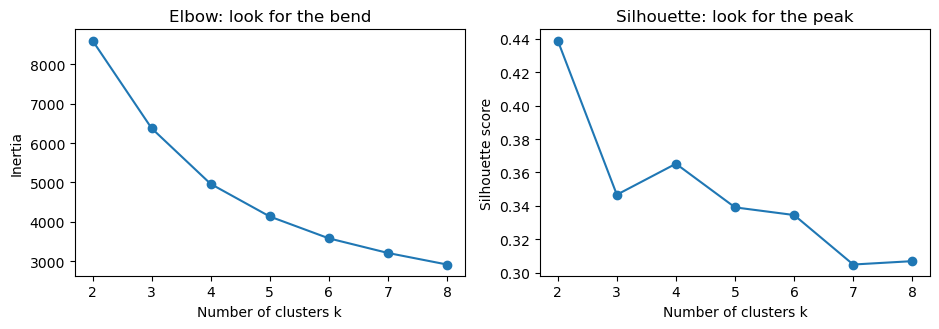

In [3]:
# Fit K-means for k = 2 to 8, and score each split two ways.
ks, inertias, silhouettes = [], [], []
for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)       # 20 random starts; keep the best
    labels = kmeans.fit_predict(X)
    ks.append(k)
    inertias.append(kmeans.inertia_)                                # total squared distance to the centers
    silhouettes.append(silhouette_score(X, labels))                 # +1 well separated, 0 overlapping
    print(f"k={k}  inertia={kmeans.inertia_:.1f}  silhouette={silhouettes[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
axes[0].plot(ks, inertias, marker="o")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow: look for the bend")
axes[1].plot(ks, silhouettes, marker="o")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette: look for the peak")
plt.tight_layout()
plt.savefig(RESULTS / "elbow_and_silhouette.png", dpi=160, bbox_inches="tight")
plt.show()

### Question 4 — Compare K-means with DBSCAN

K-means with four segments, against DBSCAN, which finds dense regions and leaves the rest as *noise*. Here noise is not an error: it is the customers who look like no one else.

In [4]:
# K-means with four segments: every customer is placed in one of them.
kmeans = KMeans(n_clusters=4, n_init=20, random_state=42)
k_labels = kmeans.fit_predict(X)
print("K-means (k=4) silhouette:", round(silhouette_score(X, k_labels), 3))

# DBSCAN: dense groups only. A customer with fewer than 10 others within 0.5 is labeled -1, noise.
dbscan = DBSCAN(eps=0.5, min_samples=10)
d_labels = dbscan.fit_predict(X)
is_noise = d_labels == -1
noise_revenue = customers.loc[is_noise, "spend"].sum() / customers["spend"].sum()
print("DBSCAN clusters:", len(set(d_labels[~is_noise])), " noise customers:", int(is_noise.sum()),
      " their share of revenue:", round(noise_revenue, 3))
print("noise customers' median orders and spend:",
      customers.loc[is_noise, ["orders", "spend"]].median().round(0).to_dict())

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=23.
  warnings.warn(


K-means (k=4) silhouette: 0.365
DBSCAN clusters: 2  noise customers: 91  their share of revenue: 0.308
noise customers' median orders and spend: {'orders': 29.0, 'spend': 23419.0}


### Question 5 — Describe the segments

Medians describe each K-means segment in its own units, with its share of the shop's revenue.

In [5]:
# Describe each K-means segment by its typical customer, and its share of all revenue.
segments = customers.assign(kmeans_cluster=k_labels, dbscan_cluster=d_labels)
profile = segments.groupby("kmeans_cluster").agg(
    customers=("orders", "size"),
    recency_days=("recency_days", "median"),
    orders=("orders", "median"),
    spend=("spend", "median"),
    revenue=("spend", "sum"),
)
profile["revenue_share"] = (profile.pop("revenue") / customers["spend"].sum()).round(3)
print(profile.round({"recency_days": 0, "orders": 0, "spend": 0, "revenue_share": 3}).to_string())

                customers  recency_days  orders   spend  revenue_share
kmeans_cluster                                                        
0                    2056         400.0     1.0   291.0          0.040
1                    1474         162.0     5.0  1587.0          0.179
2                    1117          15.0    13.0  5232.0          0.721
3                    1231          23.0     3.0   721.0          0.059


### Question 6 — Plot both clusterings

Orders against spend, on log scales, coloured by each method's labels.

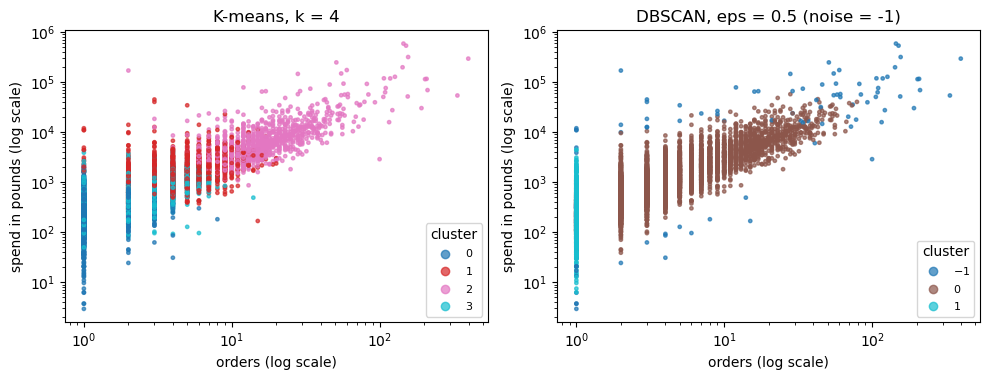

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
clusterings = [(axes[0], k_labels, "K-means, k = 4"),
               (axes[1], d_labels, "DBSCAN, eps = 0.5 (noise = -1)")]
for ax, labels, title in clusterings:
    scatter = ax.scatter(customers["orders"], customers["spend"], c=labels, cmap="tab10", s=6, alpha=0.7)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("orders (log scale)")
    ax.set_ylabel("spend in pounds (log scale)")
    ax.set_title(title)
    ax.legend(*scatter.legend_elements(), title="cluster", fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(RESULTS / "kmeans_and_dbscan_segments.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** 1,067,371 invoice lines become 779,425 clean sales from 5,878 customers: 22.8% of lines have no customer ID, 1.8% are cancellations, and 34,335 are exact duplicates. The silhouette peaks at $k=2$ (0.439), and among richer splits $k=4$ (0.365) beats 3 and 5. Four segments tell a business story: 2,056 lost one-time buyers (median 400 days since their only order, 4.0% of revenue), 1,474 lapsing regulars (162 days, 5 orders, 17.9%), 1,231 recent occasional buyers (23 days, 3 orders, 5.9%), and 1,117 best customers (15 days, 13 orders, a median spend of £5,232 and 72.1% of all revenue). DBSCAN finds 2 dense clusters and labels 91 customers as noise, with a median of 29 orders and £23,419 spend: the shop's wholesale buyers, 1.5% of customers carrying 30.8% of revenue. A method that is allowed to say *none of the above* found the customers who matter most.

**Checkpoint: before you move on**

- 779,425 clean lines from 5,878 customers.
- The silhouette peaks at $k=2$ (0.439); $k=4$ scores 0.365.
- DBSCAN leaves 91 customers as noise, and they bring 30.8% of the revenue.

## Part B — PCA on wood-defect images

**Goal.** Compress 3,072 pixels with PCA, choose how much to keep on validation, and open the test images once.

*Questions 7–11 · Data: wood surface defects*

### Question 7 — Load the images

The source holds 20,276 photos of sawn boards, collected for automated quality control, with a box around each defect. The course file holds 15,701 of those defects, cut out and shrunk to 32 by 32 colour pixels, in seven types. Most boards carry several defects, so whole boards go to one side of each split: a defect never meets its neighbour from the same board on the other side. The test images stay closed until Question 9.

images: (15701, 32, 32, 3)  boards: 10358
per defect type: {'live knot': 3000, 'dead knot': 3000, 'resin': 3000, 'knot with crack': 2276, 'crack': 2169, 'marrow': 1181, 'quartzity': 1075}
12567 development and 3134 test images; boards in both: 0


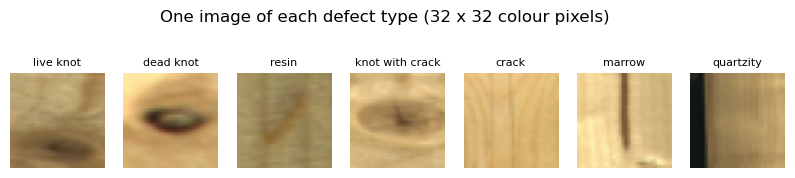

In [7]:
wood = np.load(DATA / "unsupervised/wood_surface_defects/wood_defects.npz")
images, labels, boards = wood["x"], wood["y"], wood["board"]
class_names = [str(name) for name in wood["classes"]]
print("images:", images.shape, " boards:", len(np.unique(boards)))
print("per defect type:", dict(zip(class_names, np.bincount(labels).tolist())))

# Each 32 x 32 colour image becomes one row of 32 * 32 * 3 = 3,072 numbers, and 0-255 becomes 0-1.
X_all = images.reshape(len(images), -1) / 255.0

# Most boards have several defects, so whole boards go to one side of each split: no board is in both.
dev_rows, test_rows = next(GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42).split(X_all, labels, boards))
X_dev, y_dev, b_dev = X_all[dev_rows], labels[dev_rows], boards[dev_rows]
X_test, y_test = X_all[test_rows], labels[test_rows]
print(len(X_dev), "development and", len(X_test), "test images; boards in both:",
      len(set(b_dev) & set(boards[test_rows])))

fig, axes = plt.subplots(1, 7, figsize=(10, 1.9))
for ax, k in zip(axes, range(7)):
    first = np.flatnonzero(labels == k)[0]                  # the first image of each defect type
    ax.imshow(images[first])
    ax.set_title(class_names[k], fontsize=8)
    ax.axis("off")
plt.suptitle("One image of each defect type (32 x 32 colour pixels)", y=1.08)
plt.savefig(RESULTS / "one_image_of_each_defect_type.png", dpi=160, bbox_inches="tight")
plt.show()

### Question 8 — Choose a PCA budget on validation

How much variance to keep is a hyperparameter, so it is chosen on validation rows: a quarter of the development boards, split off the same way. Logistic regression on all 3,072 pixels is the reference; with that many inputs it needs up to 3,000 steps to converge.

In [8]:
# Choose the budget on a split of the development images, again board by board.
fit_rows, valid_rows = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42).split(X_dev, y_dev, b_dev))
X_fit, y_fit = X_dev[fit_rows], y_dev[fit_rows]
X_valid, y_valid = X_dev[valid_rows], y_dev[valid_rows]

baseline = LogisticRegression(max_iter=3000)              # 3,072 inputs need more steps to converge
baseline.fit(X_fit, y_fit)
print("all 3,072 pixels: validation accuracy =", round(accuracy_score(y_valid, baseline.predict(X_valid)), 4))

# PCA keeps as many components as it needs to hold the given share of the variance.
for retained_variance in [0.90, 0.95, 0.99]:
    candidate = Pipeline([
        ("pca", PCA(n_components=retained_variance, svd_solver="full")),
        ("model", LogisticRegression(max_iter=1000)),
    ])
    candidate.fit(X_fit, y_fit)
    n_kept = candidate.named_steps["pca"].n_components_
    accuracy = accuracy_score(y_valid, candidate.predict(X_valid))
    print(f"{retained_variance:.0%} variance: {n_kept:3d} components, validation accuracy = {accuracy:.4f}")

all 3,072 pixels: validation accuracy = 0.6168


90% variance:  21 components, validation accuracy = 0.5701


95% variance:  50 components, validation accuracy = 0.5919


99% variance: 248 components, validation accuracy = 0.6072


### Question 9 — Open the test images once

The chosen budget, 99% of the variance, is refit on all the development images and scored once on the test boards, next to logistic regression on all 3,072 pixels.

In [9]:
# The chosen budget, 99%, refitted on all the development images; the plain model too, for comparison.
final_model = Pipeline([
    ("pca", PCA(n_components=0.99, svd_solver="full")),
    ("model", LogisticRegression(max_iter=1000)),
])
final_model.fit(X_dev, y_dev)
full_model = LogisticRegression(max_iter=3000)
full_model.fit(X_dev, y_dev)
pca = final_model.named_steps["pca"]

print(f"FINAL TEST ({len(X_test):,} images from boards never seen in development)")
print("all 3,072 pixels accuracy:", round(accuracy_score(y_test, full_model.predict(X_test)), 4))
print("PCA components kept:", pca.n_components_, " variance retained:", round(pca.explained_variance_ratio_.sum(), 4))
print("PCA -> logistic accuracy:", round(accuracy_score(y_test, final_model.predict(X_test)), 4))
print("recall per defect type:", dict(zip(class_names, recall_score(y_test, final_model.predict(X_test), average=None).round(2).tolist())))

FINAL TEST (3,134 images from boards never seen in development)
all 3,072 pixels accuracy: 0.6375
PCA components kept: 253  variance retained: 0.99
PCA -> logistic accuracy: 0.6331
recall per defect type: {'live knot': 0.56, 'dead knot': 0.69, 'resin': 0.73, 'knot with crack': 0.43, 'crack': 0.72, 'marrow': 0.74, 'quartzity': 0.58}


### Question 10 — See what 99% looks like

Rebuild eight test images from 90% and from 99% of the variance to see what each keeps, and draw how the variance accumulates over the 3,072 directions.

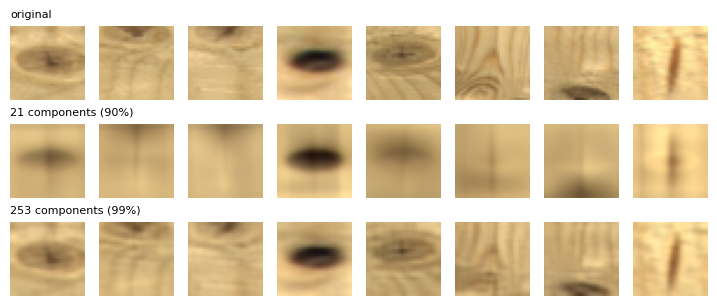

components for 50%, 80%, 90%, 95% and 99% of the variance: [2, 8, 21, 51, 253]
the first three components hold 0.624 of the variance


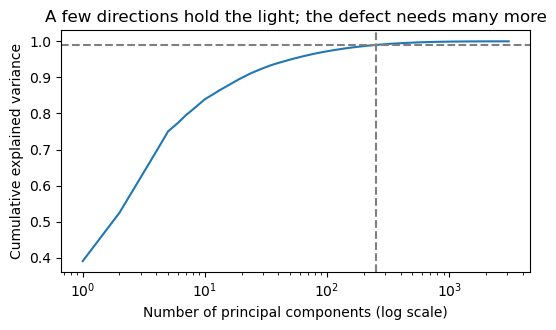

In [10]:
# Compress eight test images to a few components and to the kept ones, then expand them back to 3,072 numbers.
few = PCA(n_components=0.90, svd_solver="full").fit(X_dev)
rows = [("original", X_test[:8]),
        (f"{few.n_components_} components (90%)", few.inverse_transform(few.transform(X_test[:8]))),
        (f"{pca.n_components_} components (99%)", pca.inverse_transform(pca.transform(X_test[:8])))]

fig, axes = plt.subplots(3, 8, figsize=(9, 3.6))
for i, (title, batch) in enumerate(rows):
    for j in range(8):
        axes[i, j].imshow(np.clip(batch[j].reshape(32, 32, 3), 0, 1))
        axes[i, j].axis("off")
    axes[i, 0].set_title(title, fontsize=8, loc="left")
plt.savefig(RESULTS / "originals_and_rebuilt_images.png", dpi=160, bbox_inches="tight")
plt.show()

# All components on the development images: how many are needed for each share of the variance?
all_components = PCA(svd_solver="full").fit(X_dev)
cumulative = np.cumsum(all_components.explained_variance_ratio_)
needed = [int(np.searchsorted(cumulative, share) + 1) for share in (0.50, 0.80, 0.90, 0.95, 0.99)]
print("components for 50%, 80%, 90%, 95% and 99% of the variance:", needed)
print("the first three components hold", round(cumulative[2], 3), "of the variance")

plt.figure(figsize=(5.5, 3.4))
plt.plot(np.arange(1, len(cumulative) + 1), cumulative)
plt.xscale("log")
plt.axhline(0.99, linestyle="--", color="grey")
plt.axvline(pca.n_components_, linestyle="--", color="grey")
plt.xlabel("Number of principal components (log scale)")
plt.ylabel("Cumulative explained variance")
plt.title("A few directions hold the light; the defect needs many more")
plt.tight_layout()
plt.savefig(RESULTS / "cumulative_explained_variance.png", dpi=160, bbox_inches="tight")
plt.show()

### Question 11 — Save and reload the model

Save the pipeline, reload it, and check that it still names the first test images.

In [11]:
# Save the PCA and the classifier together, load them back, and predict five test images.
model_path = MODELS / "wood_pca_logistic.joblib"
joblib.dump(final_model, model_path)

loaded = joblib.load(model_path)
print("file size (MB):", round(model_path.stat().st_size / 1e6, 2))
print("predicted:", [class_names[i] for i in loaded.predict(X_test[:5])])
print("actual:   ", [class_names[i] for i in y_test[:5]])

file size (MB): 6.26
predicted: ['knot with crack', 'knot with crack', 'dead knot', 'dead knot', 'knot with crack']
actual:    ['knot with crack', 'knot with crack', 'knot with crack', 'dead knot', 'knot with crack']


**What the output shows.** 15,701 images from 10,358 boards; 12,567 develop and 3,134 test, with no board on both sides. On validation, logistic regression on all 3,072 pixels scores 0.617; keeping 90% of the variance takes only 21 components but scores 0.570, 95% (50 components) 0.592, and 99% (248 components) 0.607. The first directions describe the light and colour of the wood, not the shape of a defect, so the budget is 99%. On the test boards, 253 components score 0.633 against 0.638 for every pixel: half a point for a twelvefold compression. Knots with cracks are the hardest type (recall 0.43). Half the variance lives in 2 directions and 90% in 21, and the rebuilt images show it: 21 components keep a soft brown blur, 253 bring back the rings and cracks. The 6.26 MB saved model names four of the first five test images.

**Checkpoint: before you move on**

- Keeping 99% of the variance takes 248 components and scores 0.6072 on validation, against 0.6168 for all pixels.
- On the test boards: 0.6375 for all pixels and 0.6331 with 253 components.

## Evidence

Write the numbers above to the results folder. These files are regenerated on every run; do not edit them by hand.

### Question 12 — Save the evidence

In [12]:
diagnostics = pd.DataFrame({"k": ks, "inertia": inertias, "silhouette": silhouettes})
diagnostics.round(4).to_csv(RESULTS / "kmeans_diagnostics.csv", index=False)
profile.to_csv(RESULTS / "customer_segments.csv")
variance_table = pd.DataFrame({"component": np.arange(1, len(cumulative) + 1), "cumulative_variance": cumulative})
variance_table.round(4).to_csv(RESULTS / "pca_cumulative_variance.csv", index=False)
metrics = pd.DataFrame([
    {"dataset": "wood_surface_defects (test boards)", "model": "logistic, 3,072 pixels",
     "test_accuracy": accuracy_score(y_test, full_model.predict(X_test))},
    {"dataset": "wood_surface_defects (test boards)", "model": f"PCA({pca.n_components_}) -> logistic",
     "test_accuracy": accuracy_score(y_test, final_model.predict(X_test))},
])
metrics.round(4).to_csv(RESULTS / "metrics.csv", index=False)
print("Saved:", sorted(p.name for p in RESULTS.iterdir()))

Saved: ['cumulative_explained_variance.png', 'customer_segments.csv', 'elbow_and_silhouette.png', 'kmeans_and_dbscan_segments.png', 'kmeans_diagnostics.csv', 'metrics.csv', 'one_image_of_each_defect_type.png', 'originals_and_rebuilt_images.png', 'pca_cumulative_variance.csv']


## Try it yourself

Cluster images without their labels. Reduce the Question 8 fitting images to 50 PCA components, run K-means with 7 clusters, one per defect type, and only then compare the clusters with the true types, with the adjusted Rand index and a table of what each cluster contains.

Attempt it in the cell below before reading the solution.

### Question 13 — Try it yourself

In [13]:
# Your work here

### One solution

### Question 14 — One solution

adjusted Rand index against the true defect types: 0.129
         images most common type  purity
cluster                                 
2          1570        dead knot    0.56
1          1630        live knot    0.46
3          1048            resin    0.39
6          2077            crack    0.36
4          2277            resin    0.32
5           375        quartzity    0.28
0           380            resin    0.27


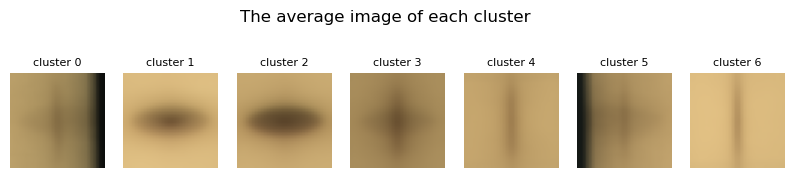

In [14]:
# Cluster the development images without their labels, then ask what the clusters contain.
codes = PCA(n_components=50, random_state=42).fit_transform(X_fit)          # 50 numbers per image
image_clusters = KMeans(n_clusters=7, n_init=10, random_state=42).fit_predict(codes)
print("adjusted Rand index against the true defect types:", round(adjusted_rand_score(y_fit, image_clusters), 3))

# Count the true types inside each cluster; purity is the share of its most common type.
table = pd.crosstab(pd.Series(image_clusters, name="cluster"), pd.Categorical.from_codes(y_fit, class_names))
summary = pd.DataFrame({
    "images": table.sum(axis=1),
    "most common type": table.idxmax(axis=1),
    "purity": (table.max(axis=1) / table.sum(axis=1)).round(2),
})
print(summary.sort_values("purity", ascending=False).to_string())

# What does each cluster look like? Its average image.
fig, axes = plt.subplots(1, 7, figsize=(10, 1.9))
for ax, c in zip(axes, range(7)):
    ax.imshow(X_fit[image_clusters == c].mean(axis=0).reshape(32, 32, 3))
    ax.set_title(f"cluster {c}", fontsize=8)
    ax.axis("off")
plt.suptitle("The average image of each cluster", y=1.08)
plt.savefig(RESULTS / "the_average_image_of_each_cluster.png", dpi=160, bbox_inches="tight")
plt.show()

**What it shows.** The clusters barely match the types: an adjusted Rand index of 0.129, where 1 would be the types exactly and 0 a random split, and the purest cluster is only 56% dead knots. The average images show why: K-means grouped the defects by brightness, colour and the direction of the grain, which is what varies most in pixels, not by what a grader calls a defect. Without labels, *similar* means similar pixels.